# Load Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sqlalchemy import create_engine
import warnings

df_matches = pd.read_csv("matches.csv")
df_deliveries = pd.read_csv("deliveries.csv")
print("successfully load")

successfully load


# Data cleaning of df_matches table

In [2]:
df_matches.shape

(1095, 20)

In [3]:
df_matches.columns

Index(['id', 'season', 'city', 'date', 'match_type', 'player_of_match',
       'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner',
       'result', 'result_margin', 'target_runs', 'target_overs', 'super_over',
       'method', 'umpire1', 'umpire2'],
      dtype='str')

In [4]:
# df_matches.head()
df_matches.tail()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
1090,1426307,2024,Hyderabad,2024-05-19,League,Abhishek Sharma,"Rajiv Gandhi International Stadium, Uppal, Hyd...",Punjab Kings,Sunrisers Hyderabad,Punjab Kings,bat,Sunrisers Hyderabad,wickets,4.0,215.0,20.0,N,NaN,Nitin Menon,VK Sharma
1091,1426309,2024,Ahmedabad,2024-05-21,Qualifier 1,MA Starc,"Narendra Modi Stadium, Ahmedabad",Sunrisers Hyderabad,Kolkata Knight Riders,Sunrisers Hyderabad,bat,Kolkata Knight Riders,wickets,8.0,160.0,20.0,N,NaN,AK Chaudhary,R Pandit
1092,1426310,2024,Ahmedabad,2024-05-22,Eliminator,R Ashwin,"Narendra Modi Stadium, Ahmedabad",Royal Challengers Bengaluru,Rajasthan Royals,Rajasthan Royals,field,Rajasthan Royals,wickets,4.0,173.0,20.0,N,NaN,KN Ananthapadmanabhan,MV Saidharshan Kumar
1093,1426311,2024,Chennai,2024-05-24,Qualifier 2,Shahbaz Ahmed,"MA Chidambaram Stadium, Chepauk, Chennai",Sunrisers Hyderabad,Rajasthan Royals,Rajasthan Royals,field,Sunrisers Hyderabad,runs,36.0,176.0,20.0,N,NaN,Nitin Menon,VK Sharma
1094,1426312,2024,Chennai,2024-05-26,Final,MA Starc,"MA Chidambaram Stadium, Chepauk, Chennai",Sunrisers Hyderabad,Kolkata Knight Riders,Sunrisers Hyderabad,bat,Kolkata Knight Riders,wickets,8.0,114.0,20.0,N,NaN,J Madanagopal,Nitin Menon


In [5]:
df_matches.info()

<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   str    
 2   city             1044 non-null   str    
 3   date             1095 non-null   str    
 4   match_type       1095 non-null   str    
 5   player_of_match  1090 non-null   str    
 6   venue            1095 non-null   str    
 7   team1            1095 non-null   str    
 8   team2            1095 non-null   str    
 9   toss_winner      1095 non-null   str    
 10  toss_decision    1095 non-null   str    
 11  winner           1090 non-null   str    
 12  result           1095 non-null   str    
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   str    
 17  method           21 non-n

In [6]:
df_matches.drop(columns = ["method", "umpire1", "umpire2"], inplace = True)

In [7]:
df_matches.shape

(1095, 17)

In [8]:
df_matches.rename(columns = {"venue" : "stadium_name", "result" : "win_type", "id" : "match_id"}, inplace = True)

In [9]:
df_matches["city"].unique()

<StringArray>
[     'Bangalore',     'Chandigarh',          'Delhi',         'Mumbai',
        'Kolkata',         'Jaipur',      'Hyderabad',        'Chennai',
      'Cape Town', 'Port Elizabeth',         'Durban',      'Centurion',
    'East London',   'Johannesburg',      'Kimberley',   'Bloemfontein',
      'Ahmedabad',        'Cuttack',         'Nagpur',     'Dharamsala',
          'Kochi',         'Indore',  'Visakhapatnam',           'Pune',
         'Raipur',         'Ranchi',      'Abu Dhabi',              nan,
         'Rajkot',         'Kanpur',      'Bengaluru',          'Dubai',
        'Sharjah',    'Navi Mumbai',        'Lucknow',       'Guwahati',
         'Mohali']
Length: 37, dtype: str

In [10]:
df_matches["city"] = df_matches["city"].replace("Bangalore", "Bengaluru")

In [11]:
df_matches["city"].nunique(dropna = False)

36

In [12]:
df_matches["match_type"].unique()

<StringArray>
[            'League',         'Semi Final',              'Final',
 '3rd Place Play-Off',        'Qualifier 1',  'Elimination Final',
        'Qualifier 2',         'Eliminator']
Length: 8, dtype: str

In [13]:
df_matches["match_type"] = df_matches["match_type"].replace("Elimination Final", "Eliminator")

In [14]:
df_matches["match_type"].unique()

<StringArray>
[            'League',         'Semi Final',              'Final',
 '3rd Place Play-Off',        'Qualifier 1',         'Eliminator',
        'Qualifier 2']
Length: 7, dtype: str

In [15]:
df_matches["stadium_name"].unique()

<StringArray>
[                                                'M Chinnaswamy Stadium',
                            'Punjab Cricket Association Stadium, Mohali',
                                                      'Feroz Shah Kotla',
                                                      'Wankhede Stadium',
                                                          'Eden Gardens',
                                                'Sawai Mansingh Stadium',
                             'Rajiv Gandhi International Stadium, Uppal',
                                       'MA Chidambaram Stadium, Chepauk',
                                            'Dr DY Patil Sports Academy',
                                                              'Newlands',
                                                      'St George's Park',
                                                             'Kingsmead',
                                                       'SuperSport Park',
                        

In [16]:
stadium_mapping = {
    # Chinnaswamy 
    'M Chinnaswamy Stadium': 'Chinnaswamy Stadium',
    'M.Chinnaswamy Stadium': 'Chinnaswamy Stadium',
    'M. Chinnaswamy Stadium': 'Chinnaswamy Stadium',
    'M Chinnaswamy Stadium, Bengaluru': 'Chinnaswamy Stadium',
    
    # Delhi 
    'Feroz Shah Kotla': 'Arun Jaitley Stadium',
    'Arun Jaitley Stadium, Delhi': 'Arun Jaitley Stadium',
    'Arun Jaitley Stadium': 'Arun Jaitley Stadium',
    
    # Ahmedabad 
    'Sardar Patel Stadium, Motera': 'Narendra Modi Stadium',
    'Narendra Modi Stadium, Ahmedabad': 'Narendra Modi Stadium',
    
    # Mohali / Punjab 
    'Punjab Cricket Association Stadium, Mohali': 'PCA Stadium, Mohali',
    'Punjab Cricket Association IS Bindra Stadium, Mohali': 'PCA Stadium, Mohali',
    'Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh': 'PCA Stadium, Mohali',
    'Punjab Cricket Association IS Bindra Stadium': 'PCA Stadium, Mohali',
    
    #  Wankhede and Eden Gardens 
    'Wankhede Stadium': 'Wankhede Stadium',
    'Wankhede Stadium, Mumbai': 'Wankhede Stadium',
    'Eden Gardens': 'Eden Gardens',
    'Eden Gardens, Kolkata': 'Eden Gardens',
    
    # Chennai 
    'MA Chidambaram Stadium, Chepauk': 'Chepauk Stadium',
    'MA Chidambaram Stadium, Chepauk, Chennai': 'Chepauk Stadium',
    'MA Chidambaram Stadium': 'Chepauk Stadium',
    
    # Hyderabad 
    'Rajiv Gandhi International Stadium, Uppal': 'Rajiv Gandhi Stadium',
    'Rajiv Gandhi International Stadium, Uppal, Hyderabad': 'Rajiv Gandhi Stadium',
    'Rajiv Gandhi International Stadium': 'Rajiv Gandhi Stadium',
    
    #  Lucknow 
    'Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow': 'Ekana Stadium',
    
    #  Mullanpur and Visakhapatnam 
    'Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur': 'Mullanpur Stadium',
    'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam': 'Vizag Stadium',
    'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium': 'Vizag Stadium',
    
    # Mumbai, Pune and Dharamshala 
    'Dr DY Patil Sports Academy': 'DY Patil Stadium',
    'Dr DY Patil Sports Academy, Mumbai': 'DY Patil Stadium',
    'Maharashtra Cricket Association Stadium': 'MCA Stadium, Pune',
    'Maharashtra Cricket Association Stadium, Pune': 'MCA Stadium, Pune',
    'Subrata Roy Sahara Stadium': 'Sahara Stadium, Pune',
    'Subrata Roy Sahara Stadium, Pune': 'Sahara Stadium, Pune',
    'Himachal Pradesh Cricket Association Stadium': 'HPCA Stadium, Dharamshala',
    'Himachal Pradesh Cricket Association Stadium, Dharamsala': 'HPCA Stadium, Dharamshala',
    
    # Baki aur Unique Stadiums 
    'Sawai Mansingh Stadium': 'SMS Stadium, Jaipur',
    'Sawai Mansingh Stadium, Jaipur': 'SMS Stadium, Jaipur',
    'Vidarbha Cricket Association Stadium, Jamtha': 'VCA Stadium, Nagpur',
    'JSCA International Stadium Complex': 'JSCA Stadium, Ranchi',
    'Shaheed Veer Narayan Singh International Stadium': 'Raipur Stadium',
    'Saurashtra Cricket Association Stadium': 'SCA Stadium, Rajkot',
    'Barsapara Cricket Stadium, Guwahati': 'Barsapara Stadium',
    'Holkar Cricket Stadium': 'Holkar Stadium, Indore',
    'Barabati Stadium': 'Barabati Stadium, Cuttack',
    'Nehru Stadium': 'Nehru Stadium',
    'Green Park': 'Green Park, Kanpur',

    #  UAE / Dubai 
    'Dubai International Cricket Stadium': 'Dubai Stadium',
    'Sheikh Zayed Stadium': 'Zayed Stadium',
    'Zayed Cricket Stadium, Abu Dhabi': 'Zayed Stadium',
    'Sharjah Cricket Stadium': 'Sharjah Stadium',

    # South Africa ke Stadiums 
    'Newlands': 'Newlands, Cape Town',
    'St George\'s Park': 'St George\'s Park',
    'Kingsmead': 'Kingsmead, Durban',
    'SuperSport Park': 'SuperSport Park',
    'Buffalo Park': 'Buffalo Park',
    'New Wanderers Stadium': 'Wanderers Stadium',
    'De Beers Diamond Oval': 'Diamond Oval',
    'OUTsurance Oval': 'OUTsurance Oval'
}

In [17]:
df_matches["stadium_name"] = df_matches["stadium_name"].replace(stadium_mapping)

In [18]:
df_matches["stadium_name"].unique()

<StringArray>
[      'Chinnaswamy Stadium',       'PCA Stadium, Mohali',
      'Arun Jaitley Stadium',          'Wankhede Stadium',
              'Eden Gardens',       'SMS Stadium, Jaipur',
      'Rajiv Gandhi Stadium',           'Chepauk Stadium',
          'DY Patil Stadium',       'Newlands, Cape Town',
          'St George's Park',         'Kingsmead, Durban',
           'SuperSport Park',              'Buffalo Park',
         'Wanderers Stadium',              'Diamond Oval',
           'OUTsurance Oval',         'Brabourne Stadium',
     'Narendra Modi Stadium', 'Barabati Stadium, Cuttack',
 'Brabourne Stadium, Mumbai',       'VCA Stadium, Nagpur',
 'HPCA Stadium, Dharamshala',             'Nehru Stadium',
    'Holkar Stadium, Indore',             'Vizag Stadium',
      'Sahara Stadium, Pune',         'MCA Stadium, Pune',
            'Raipur Stadium',      'JSCA Stadium, Ranchi',
             'Zayed Stadium',           'Sharjah Stadium',
             'Dubai Stadium',       'SCA S

In [19]:
df_matches["team1"].unique()

<StringArray>
['Royal Challengers Bangalore',             'Kings XI Punjab',
            'Delhi Daredevils',              'Mumbai Indians',
       'Kolkata Knight Riders',            'Rajasthan Royals',
             'Deccan Chargers',         'Chennai Super Kings',
        'Kochi Tuskers Kerala',               'Pune Warriors',
         'Sunrisers Hyderabad',               'Gujarat Lions',
     'Rising Pune Supergiants',      'Rising Pune Supergiant',
              'Delhi Capitals',                'Punjab Kings',
        'Lucknow Super Giants',              'Gujarat Titans',
 'Royal Challengers Bengaluru']
Length: 19, dtype: str

In [20]:
df_matches["team2"].unique()

<StringArray>
[      'Kolkata Knight Riders',         'Chennai Super Kings',
            'Rajasthan Royals', 'Royal Challengers Bangalore',
             'Deccan Chargers',             'Kings XI Punjab',
            'Delhi Daredevils',              'Mumbai Indians',
        'Kochi Tuskers Kerala',               'Pune Warriors',
         'Sunrisers Hyderabad',     'Rising Pune Supergiants',
               'Gujarat Lions',      'Rising Pune Supergiant',
              'Delhi Capitals',                'Punjab Kings',
              'Gujarat Titans',        'Lucknow Super Giants',
 'Royal Challengers Bengaluru']
Length: 19, dtype: str

In [21]:
team_cleaning = {
    "Royal Challengers Bangalore" : "Royal Challengers Bengaluru",
    "Delhi Daredevils" : "Delhi Capitals",
    "Kings XI Punjab" : "Punjab Kings",
    "Rising Pune Supergiant" : "Rising Pune Supergiants"
}

In [22]:
print(df_matches["team1"].nunique())
print(df_matches["team2"].nunique())
print(df_matches["toss_winner"].nunique()) 
print(df_matches["winner"].nunique(dropna = False))

19
19
19
20


In [23]:
df_matches["team1"] = df_matches["team1"].replace(team_cleaning)
df_matches["team2"] = df_matches["team2"].replace(team_cleaning)
df_matches["winner"] = df_matches["winner"].replace(team_cleaning)
df_matches["toss_winner"] = df_matches["toss_winner"].replace(team_cleaning)

In [24]:
print(df_matches["team1"].nunique())
print(df_matches["team2"].nunique())
print(df_matches["toss_winner"].nunique())
print(df_matches["winner"].nunique(dropna = False))

15
15
15
16


In [25]:
df_matches["win_type"].unique()

<StringArray>
['runs', 'wickets', 'tie', 'no result']
Length: 4, dtype: str

In [26]:
df_matches[df_matches["win_type"] == "tie"]["super_over"]

66     Y
130    Y
328    Y
342    Y
416    Y
475    Y
610    Y
705    Y
746    Y
757    Y
765    Y
790    Y
791    Y
835    Y
Name: super_over, dtype: str

In [27]:
df_matches["target_overs"].unique()

array([20. , 16. ,  8. , 18. ,  6. ,  9.2, 17. , 10. , 13. ,  nan, 12. ,
        5. , 11. ,  9. , 14. , 15. ])

In [28]:
df_matches["super_over"].unique()

<StringArray>
['N', 'Y']
Length: 2, dtype: str

In [29]:
df_matches.info()

<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   match_id         1095 non-null   int64  
 1   season           1095 non-null   str    
 2   city             1044 non-null   str    
 3   date             1095 non-null   str    
 4   match_type       1095 non-null   str    
 5   player_of_match  1090 non-null   str    
 6   stadium_name     1095 non-null   str    
 7   team1            1095 non-null   str    
 8   team2            1095 non-null   str    
 9   toss_winner      1095 non-null   str    
 10  toss_decision    1095 non-null   str    
 11  winner           1090 non-null   str    
 12  win_type         1095 non-null   str    
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   str    
dtypes: float64(3), int64(1), 

In [30]:
df_matches.columns

Index(['match_id', 'season', 'city', 'date', 'match_type', 'player_of_match',
       'stadium_name', 'team1', 'team2', 'toss_winner', 'toss_decision',
       'winner', 'win_type', 'result_margin', 'target_runs', 'target_overs',
       'super_over'],
      dtype='str')

In [31]:
df_matches["season"].unique() 

<StringArray>
['2007/08',    '2009', '2009/10',    '2011',    '2012',    '2013',    '2014',
    '2015',    '2016',    '2017',    '2018',    '2019', '2020/21',    '2021',
    '2022',    '2023',    '2024']
Length: 17, dtype: str

In [32]:
warnings.filterwarnings("ignore")

In [33]:
df_matches["season"] = df_matches["season"].replace({"2007/08" : "2008", "2009/10" : "2010", "2020/21" : "2020"}, inplace = True)

In [34]:
df_matches["season"].unique()

<StringArray>
['2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016',
 '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']
Length: 17, dtype: str

In [35]:
df_matches["season"] = df_matches["season"].astype(int)

In [36]:
df_matches["season"].dtype

dtype('int64')

In [37]:
df_matches["date"] = pd.to_datetime(df_matches["date"])

In [38]:
df_matches["date"].dtype

dtype('<M8[us]')

In [39]:
# nan columns = [city, player_of_match, winner, result_margin, target_runs, target_overs,] 

In [40]:
df_matches["city"].isna().sum()

np.int64(51)

In [41]:
df_matches[df_matches["city"].isna()].head(3)

,match_id,season,city,date,match_type,player_of_match,stadium_name,team1,team2,toss_winner,toss_decision,winner,win_type,result_margin,target_runs,target_overs,super_over
399,729281,2014,NaN,2014-04-17,League,YS Chahal,Sharjah Stadium,Delhi Capitals,Royal Challengers Bengaluru,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,wickets,8.0,146.0,20.0,N
402,729287,2014,NaN,2014-04-19,League,PA Patel,Dubai Stadium,Royal Challengers Bengaluru,Mumbai Indians,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,wickets,7.0,116.0,20.0,N
403,729289,2014,NaN,2014-04-19,League,JP Duminy,Dubai Stadium,Kolkata Knight Riders,Delhi Capitals,Kolkata Knight Riders,bat,Delhi Capitals,wickets,4.0,167.0,20.0,N


In [42]:
df_matches[df_matches["city"].isna()]["stadium_name"].unique()

<StringArray>
['Sharjah Stadium', 'Dubai Stadium']
Length: 2, dtype: str

In [43]:
df_matches.loc[df_matches["stadium_name"] == "Dubai Stadium", "city"] = "Dubai"
df_matches.loc[df_matches["stadium_name"] == "Sharjah Stadium", "city"] = "Sharjah"

In [44]:
df_matches["city"].isna().sum()

np.int64(0)

In [45]:
df_matches["player_of_match"].isna().sum()

np.int64(5)

In [46]:
df_matches[df_matches["player_of_match"].isna()]

,match_id,season,city,date,match_type,player_of_match,stadium_name,team1,team2,toss_winner,toss_decision,winner,win_type,result_margin,target_runs,target_overs,super_over
241,501265,2011,Delhi,2011-05-21,League,NaN,Arun Jaitley Stadium,Delhi Capitals,Pune Warriors,Delhi Capitals,bat,NaN,no result,NaN,NaN,NaN,N
485,829763,2015,Bengaluru,2015-04-29,League,NaN,Chinnaswamy Stadium,Royal Challengers Bengaluru,Rajasthan Royals,Rajasthan Royals,field,NaN,no result,NaN,NaN,NaN,N
511,829813,2015,Bengaluru,2015-05-17,League,NaN,Chinnaswamy Stadium,Royal Challengers Bengaluru,Delhi Capitals,Royal Challengers Bengaluru,field,NaN,no result,NaN,188.0,20.0,N
744,1178424,2019,Bengaluru,2019-04-30,League,NaN,Chinnaswamy Stadium,Royal Challengers Bengaluru,Rajasthan Royals,Rajasthan Royals,field,NaN,no result,NaN,63.0,5.0,N
994,1359519,2023,Lucknow,2023-05-03,League,NaN,Ekana Stadium,Lucknow Super Giants,Chennai Super Kings,Chennai Super Kings,field,NaN,no result,NaN,NaN,NaN,N


In [47]:
df_matches["winner"].isna().sum()

np.int64(5)

In [48]:
df_matches["player_of_match"] = df_matches["player_of_match"].fillna("no_award")
df_matches["winner"] = df_matches["winner"].fillna("no_result")

In [49]:
print(df_matches["player_of_match"].isna().sum())
print(df_matches["winner"].isna().sum())

0
0


In [50]:
df_matches["result_margin"].isna().sum()

np.int64(19)

In [51]:
df_matches[df_matches["result_margin"].isna()].head()

,match_id,season,city,date,match_type,player_of_match,stadium_name,team1,team2,toss_winner,toss_decision,winner,win_type,result_margin,target_runs,target_overs,super_over
66,392190,2009,Cape Town,2009-04-23,League,YK Pathan,"Newlands, Cape Town",Kolkata Knight Riders,Rajasthan Royals,Kolkata Knight Riders,field,Rajasthan Royals,tie,NaN,151.0,20.0,Y
130,419121,2010,Chennai,2010-03-21,League,J Theron,Chepauk Stadium,Chennai Super Kings,Punjab Kings,Chennai Super Kings,field,Punjab Kings,tie,NaN,137.0,20.0,Y
241,501265,2011,Delhi,2011-05-21,League,no_award,Arun Jaitley Stadium,Delhi Capitals,Pune Warriors,Delhi Capitals,bat,no_result,no result,NaN,NaN,NaN,N
328,598004,2013,Hyderabad,2013-04-07,League,GH Vihari,Rajiv Gandhi Stadium,Sunrisers Hyderabad,Royal Challengers Bengaluru,Royal Challengers Bengaluru,bat,Sunrisers Hyderabad,tie,NaN,131.0,20.0,Y
342,598017,2013,Bengaluru,2013-04-16,League,V Kohli,Chinnaswamy Stadium,Royal Challengers Bengaluru,Delhi Capitals,Royal Challengers Bengaluru,field,Royal Challengers Bengaluru,tie,NaN,153.0,20.0,Y


In [52]:
df_matches[df_matches["result_margin"].isna()]["win_type"].unique()

<StringArray>
['tie', 'no result']
Length: 2, dtype: str

In [53]:
df_matches[df_matches["result_margin"].isna()]["target_runs"].unique()

array([151., 137.,  nan, 131., 153., 192., 188., 154., 186.,  63., 163.,
       158., 202., 164., 177., 160.])

In [54]:
df_matches[df_matches["result_margin"].isna()]["target_overs"].unique()

array([20., nan,  5.])

In [55]:
df_matches[df_matches["target_runs"].isna()]["win_type"].unique()

<StringArray>
['no result']
Length: 1, dtype: str

In [56]:
df_matches[df_matches["target_overs"].isna()]["win_type"].unique()

<StringArray>
['no result']
Length: 1, dtype: str

In [57]:
df_matches["result_margin"] = df_matches["result_margin"].fillna(0)
df_matches["target_runs"] = df_matches["target_runs"].fillna(0)
df_matches["target_overs"] = df_matches["target_overs"].fillna(0)

In [58]:
print(df_matches["result_margin"].isna().sum())
print(df_matches["target_runs"].isna().sum())
print(df_matches["target_overs"].isna().sum())

0
0
0


In [59]:
print(df_matches.isna().values.any())

False


# Data cleaning of df_deliveries table

In [60]:
df_deliveries.shape

(260920, 17)

In [61]:
df_deliveries.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs',
       'total_runs', 'extras_type', 'is_wicket', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='str')

In [62]:
# df_deliveries.head()
df_deliveries.tail()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
260915,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,9,5,SS Iyer,AK Markram,VR Iyer,1,0,1,NaN,0,NaN,NaN,NaN
260916,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,9,6,VR Iyer,AK Markram,SS Iyer,1,0,1,NaN,0,NaN,NaN,NaN
260917,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,10,1,VR Iyer,Shahbaz Ahmed,SS Iyer,1,0,1,NaN,0,NaN,NaN,NaN
260918,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,10,2,SS Iyer,Shahbaz Ahmed,VR Iyer,1,0,1,NaN,0,NaN,NaN,NaN
260919,1426312,2,Kolkata Knight Riders,Sunrisers Hyderabad,10,3,VR Iyer,Shahbaz Ahmed,SS Iyer,1,0,1,NaN,0,NaN,NaN,NaN


In [63]:
df_deliveries.info()

<class 'pandas.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   match_id          260920 non-null  int64
 1   inning            260920 non-null  int64
 2   batting_team      260920 non-null  str  
 3   bowling_team      260920 non-null  str  
 4   over              260920 non-null  int64
 5   ball              260920 non-null  int64
 6   batter            260920 non-null  str  
 7   bowler            260920 non-null  str  
 8   non_striker       260920 non-null  str  
 9   batsman_runs      260920 non-null  int64
 10  extra_runs        260920 non-null  int64
 11  total_runs        260920 non-null  int64
 12  extras_type       14125 non-null   str  
 13  is_wicket         260920 non-null  int64
 14  player_dismissed  12950 non-null   str  
 15  dismissal_kind    12950 non-null   str  
 16  fielder           9354 non-null    str  
dtypes: int64(8), str(9)
m

In [64]:
df_deliveries.rename(columns = {"player_dismissed" : "out_batsman", "dismissal_kind" : "out_type"}, inplace = True)

In [65]:
df_deliveries["match_id"].nunique()

1095

In [66]:
df_matches["match_id"].nunique()

1095

In [67]:
df_deliveries["inning"].unique() 

array([1, 2, 3, 4, 5, 6])

In [68]:
df_deliveries["batting_team"].unique() 

<StringArray>
[      'Kolkata Knight Riders', 'Royal Challengers Bangalore',
         'Chennai Super Kings',             'Kings XI Punjab',
            'Rajasthan Royals',            'Delhi Daredevils',
              'Mumbai Indians',             'Deccan Chargers',
        'Kochi Tuskers Kerala',               'Pune Warriors',
         'Sunrisers Hyderabad',     'Rising Pune Supergiants',
               'Gujarat Lions',      'Rising Pune Supergiant',
              'Delhi Capitals',                'Punjab Kings',
        'Lucknow Super Giants',              'Gujarat Titans',
 'Royal Challengers Bengaluru']
Length: 19, dtype: str

In [69]:
df_deliveries["bowling_team"].unique() 

<StringArray>
['Royal Challengers Bangalore',       'Kolkata Knight Riders',
             'Kings XI Punjab',         'Chennai Super Kings',
            'Delhi Daredevils',            'Rajasthan Royals',
              'Mumbai Indians',             'Deccan Chargers',
        'Kochi Tuskers Kerala',               'Pune Warriors',
         'Sunrisers Hyderabad',     'Rising Pune Supergiants',
               'Gujarat Lions',      'Rising Pune Supergiant',
              'Delhi Capitals',                'Punjab Kings',
              'Gujarat Titans',        'Lucknow Super Giants',
 'Royal Challengers Bengaluru']
Length: 19, dtype: str

In [70]:
team_cleaning = {
    "Royal Challengers Bangalore" : "Royal Challengers Bengaluru",
    "Delhi Daredevils" : "Delhi Capitals",
    "Kings XI Punjab" : "Punjab Kings",
    "Rising Pune Supergiant" : "Rising Pune Supergiants"
}

In [71]:
print(df_deliveries["batting_team"].nunique())
print(df_deliveries["bowling_team"].nunique())

19
19


In [72]:
df_deliveries["batting_team"] = df_deliveries["batting_team"].replace(team_cleaning)
df_deliveries["bowling_team"] = df_deliveries["bowling_team"].replace(team_cleaning)

In [73]:
print(df_deliveries["batting_team"].nunique())
print(df_deliveries["bowling_team"].nunique())

15
15


In [74]:
df_deliveries["over"].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [75]:
df_deliveries["ball"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [76]:
df_deliveries["batter"].unique()

<StringArray>
[      'SC Ganguly',      'BB McCullum',       'RT Ponting',
        'DJ Hussey',  'Mohammad Hafeez',         'R Dravid',
         'W Jaffer',          'V Kohli',        'JH Kallis',
         'CL White',
 ...
      'LB Williams',      'AA Kulkarni',        'MJ Suthar',
       'RJ Gleeson',    'Gulbadin Naib',       'D Ferreira',
         'A Kamboj', 'T Kohler-Cadmore',     'Shivam Singh',
     'V Viyaskanth']
Length: 673, dtype: str

In [77]:
df_deliveries["bowler"].unique()

<StringArray>
[      'P Kumar',        'Z Khan',     'AA Noffke',     'JH Kallis',
      'SB Joshi',      'CL White',      'AB Dinda',      'I Sharma',
    'AB Agarkar',    'SC Ganguly',
 ...
    'N Thushara',   'LB Williams',    'RJ Gleeson',     'MJ Suthar',
      'A Kamboj',  'V Viyaskanth',   'V Kaverappa', 'Gulbadin Naib',
     'N Wadhera', 'Atharva Taide']
Length: 530, dtype: str

In [78]:
df_deliveries["batsman_runs"].unique()

array([0, 4, 6, 1, 2, 5, 3])

In [79]:
df_deliveries["extra_runs"].unique()

array([1, 0, 5, 4, 2, 3, 7])

In [80]:
df_deliveries["total_runs"].unique()

array([1, 0, 4, 6, 5, 2, 3, 7])

In [81]:
df_deliveries["extras_type"].unique()

<StringArray>
['legbyes', nan, 'wides', 'byes', 'noballs', 'penalty']
Length: 6, dtype: str

In [82]:
df_deliveries["is_wicket"].unique()

array([0, 1])

In [83]:
df_deliveries["out_type"].unique()

<StringArray>
[                    nan,                'caught',                'bowled',
               'run out',                   'lbw',          'retired hurt',
               'stumped',     'caught and bowled',            'hit wicket',
 'obstructing the field',           'retired out']
Length: 11, dtype: str

In [84]:
df_deliveries[df_deliveries["out_type"] == "retired out"]["is_wicket"].unique()

array([1])

In [85]:
df_deliveries[df_deliveries["out_type"] == "retired hurt"]["is_wicket"].unique()

array([1])

In [86]:
df_deliveries.loc[df_deliveries["out_type"] == "retired hurt", "is_wicket"] = 0

In [87]:
df_deliveries[df_deliveries["out_type"] == "retired hurt"]["is_wicket"].unique()

array([0])

In [88]:
# nan columns = [extra_type, out_batsman, out_type, fielders] 

In [89]:
df_deliveries.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs',
       'total_runs', 'extras_type', 'is_wicket', 'out_batsman', 'out_type',
       'fielder'],
      dtype='str')

In [90]:
df_deliveries["extras_type"] = df_deliveries["extras_type"].fillna("no extra")
df_deliveries["out_batsman"] = df_deliveries["out_batsman"].fillna("no wicket")
df_deliveries["out_type"] = df_deliveries["out_type"].fillna("not out")
df_deliveries["fielder"] = df_deliveries["fielder"].fillna("no fielder")

In [91]:
print(df_deliveries.isna().values.any())

False


In [92]:
print(df_matches.isna().values.any())  

False


# Data analysis and Visualization using SQl, Pandas, matplotlib, seaborn

In [93]:
df_matches.to_csv("ipl_matches.csv",  index = False)  
df_deliveries.to_csv("ipl_deliveries.csv",  index = False)

In [94]:
engine = create_engine(
    "mysql+pymysql://root:imhia-2024/sql@localhost/ipl_project"
)

#### Analysis #1: Season-wise Total Runs Trend

In [95]:
query = """select season, sum(total_runs) as total_runs
           from ipl_matches as m
           inner join ipl_deliveries as d
           on m.match_id = d.match_id
           group by season 
           order by season ;
                            """
df = pd.read_sql(query, engine)
df.head()

,season,total_runs
0,2008,17937.0
1,2009,16353.0
2,2010,18883.0
3,2011,21154.0
4,2012,22453.0


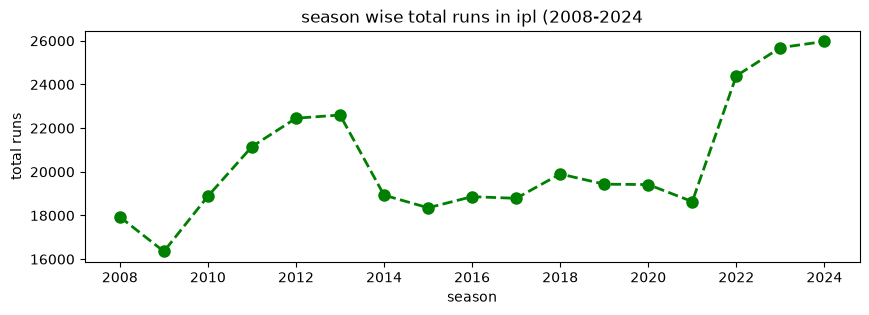

In [96]:
# Line plot
plt.figure(figsize = (10,3))
plt.plot(df["season"], df["total_runs"], color = "green", marker = "o", linestyle = "--", linewidth = 2, markersize = 8)
plt.title("season wise total runs in ipl (2008-2024")
plt.xlabel("season")
plt.ylabel("total runs")
plt.show()

#### Insights

* 2009 recorded the lowest total runs.
* A significant increase in scoring was observed after 2022.
* 2024 was the highest-scoring IPL season.

#### Conclusion

#### analysis #2 top 10 cities with most ipl matches played

In [97]:
query = """
            select city, count(*) as total_matches
            from ipl_matches 
            group by city
            order by total_matches desc
            limit 10 ;
                       """
df = pd.read_sql(query, engine)
df.head()

,city,total_matches
0,Mumbai,173
1,Bengaluru,94
2,Kolkata,93
3,Delhi,90
4,Chennai,85


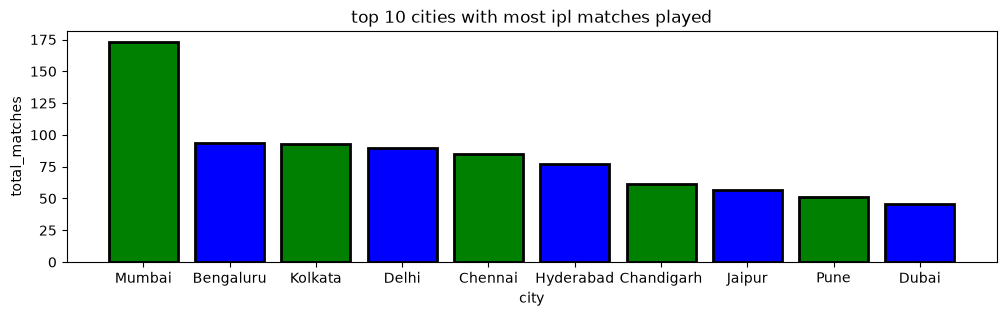

In [98]:
# Bar plot
plt.figure(figsize = (12,3))
plt.bar(df["city"],df["total_matches"], width = 0.8, color = ["green", "blue"], edgecolor = "black", linewidth = 2)
plt.title("top 10 cities with most ipl matches played")
plt.xlabel("city")
plt.ylabel("total_matches")
plt.show() 

#### Insights

#### Conclusion

#### analysis #3 top out types on which batsman get out tha most

In [99]:
query = """
            select out_type, count(*) as total_wicket,
            round(count(*) * 100/sum(count(*)) over() , 2) as wickets_percentage
            from ipl_deliveries
            where is_wicket = 1
            group by out_type 
            order by total_wicket desc ;
                                         """
df = pd.read_sql(query, engine)
df.head()

,out_type,total_wicket,wickets_percentage
0,caught,8063,62.33
1,bowled,2212,17.10
2,run out,1114,8.61
3,lbw,800,6.18
4,caught and bowled,367,2.84


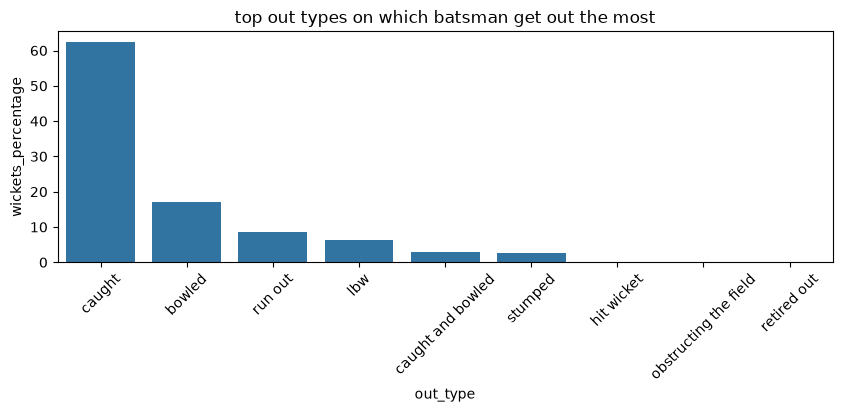

In [100]:
# Bar plot
plt.figure(figsize = (10,3))
sns.barplot(data = df, x = "out_type", y = "wickets_percentage")
plt.title('top out types on which batsman get out the most')
plt.xticks(rotation = 45)
plt.show()

#### Insights

#### Conclusion

#### analysis #4 Is there a relationship between runs scored and strike rate in IPL ?

In [101]:
query = """
            select batter, sum(batsman_runs) as runs,
            sum(case when extras_type = "wides" then 0 else 1 end) as balls,
            round((sum(batsman_runs) / sum(case when extras_type = "wides" then 0 else 1 end)) * 100, 2) as strike_rate
            from ipl_deliveries
            group by batter
            having balls >= 300
            order by strike_rate desc ;
                                       """
df = pd.read_sql(query, engine)
df.head()

,batter,runs,balls,strike_rate
0,PD Salt,653.0,372.0,175.54
1,AD Russell,2488.0,1423.0,174.84
2,TM Head,772.0,444.0,173.87
3,TH David,659.0,387.0,170.28
4,H Klaasen,993.0,590.0,168.31


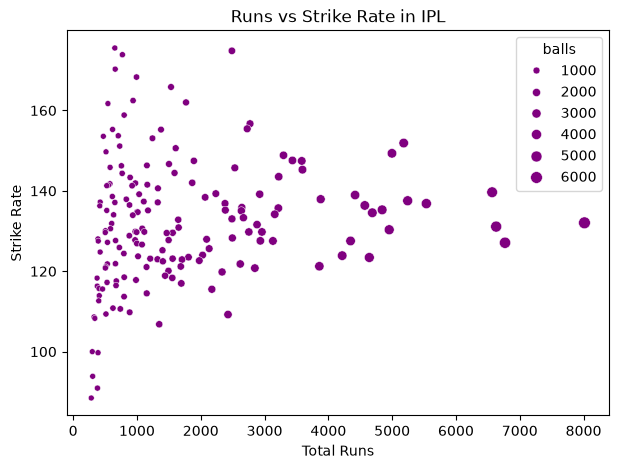

In [102]:
# scatter chart
plt.figure(figsize=(7,5))
sns.scatterplot(data = df, x = "runs", y = "strike_rate", alpha = 1, size = "balls", color = "purple")
plt.xlabel("Total Runs")
plt.ylabel("Strike Rate")
plt.title("Runs vs Strike Rate in IPL")
plt.show()

#### Insights

#### Conclusion

#### analysis #5 Who are the top 10 fielders with the most catches in IPL included wicket keeper ?

In [103]:
query = """
            select fielder, count(*) as total_caught
            from ipl_deliveries
            where out_type = "caught"
            group by fielder
            order by total_caught desc 
            limit 10;
                    """
df = pd.read_sql(query, engine)
df.head()

,fielder,total_caught
0,MS Dhoni,152
1,KD Karthik,145
2,AB de Villiers,120
3,V Kohli,114
4,SK Raina,106


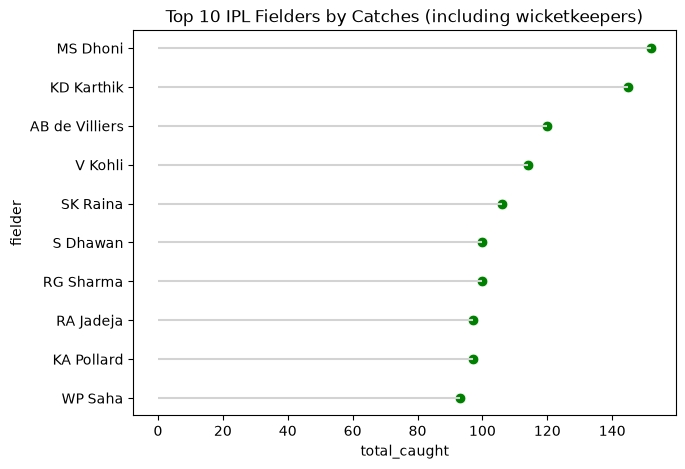

In [104]:
# lollipop chart
plt.figure(figsize = (7,5))
plt.hlines(y = df["fielder"], xmin = 0, xmax = df["total_caught"], color = "lightgray")
# plt.scatter(y = df["fielder"], x = df["total_caught"], color = "green", s = 60)
sns.scatterplot(data = df, y = "fielder", x = "total_caught", color = "green", s = 60)
plt.title("Top 10 IPL Fielders by Catches (including wicketkeepers)")
plt.show()

#### Insights

#### Conclusion

 #### analysis #6 Who are the top 10 wicket keeper with the most stumping in ipl  ?

In [105]:
query = """
            select fielder as wicket_keeper, count(*) as total_stumped,
            round(count(*) * 100 / sum(count(*)) over(), 2) as percentage
            from ipl_deliveries
            where out_type = "stumped"
            group by fielder
            order by total_stumped desc
            limit 10 ;
                      """
df = pd.read_sql(query, engine)
df.head()

,wicket_keeper,total_stumped,percentage
0,MS Dhoni,42,11.73
1,KD Karthik,37,10.34
2,RV Uthappa,32,8.94
3,WP Saha,26,7.26
4,RR Pant,23,6.42


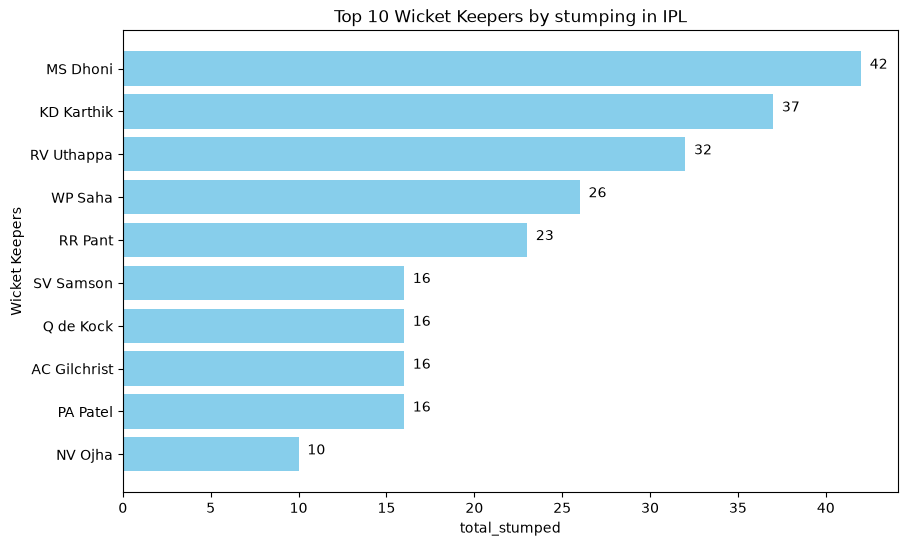

In [106]:
# Barh chart
df = df.sort_values(by = "total_stumped")
plt.figure(figsize = (10, 6))
plt.barh(df["wicket_keeper"], df["total_stumped"], color = "skyblue")
for i, v in enumerate(df["total_stumped"]):
    plt.text(v + 0.5, i, str(v))
plt.title("Top 10 Wicket Keepers by stumping in IPL")
plt.xlabel("total_stumped")
plt.ylabel("Wicket Keepers")

plt.show()

#### Insights

#### Conclusion

#### analysis #7 Analysis Does Winning the Toss Increase the Chances of Winning the Match?

In [107]:
query = """
            select case
            when toss_winner = winner then "Toss Won & Match Won"
            when toss_winner != winner then "Toss Won & Match Lost"
            end as result, count(*) as matches,
            round(count(*) * 100 / sum(count(*)) over(), 2) as matches_percentage
            from ipl_matches 
            group by result
            limit 5 ;
                    """
df = pd.read_sql(query, engine)
df.head()

,result,matches,matches_percentage
0,Toss Won & Match Lost,541,49.41
1,Toss Won & Match Won,554,50.59


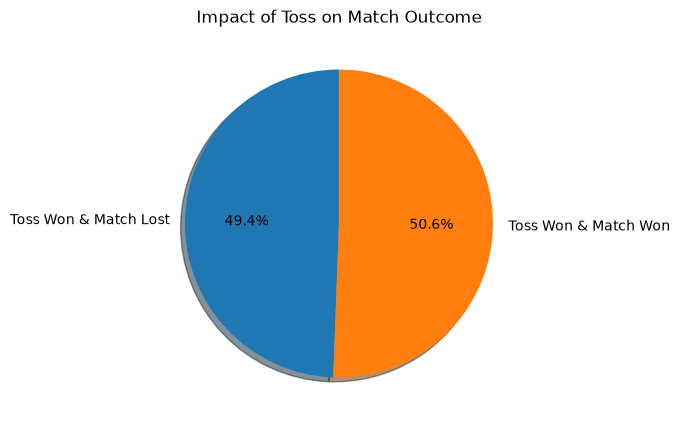

In [108]:
# Pie chart
plt.figure(figsize=(6, 5))
plt.pie(df["matches_percentage"], labels = df["result"], autopct = "%1.1f%%",startangle = 90, shadow = True)
plt.title("Impact of Toss on Match Outcome")
plt.show()

#### Insights

#### Conclusion

#### analysis #8 After Winning the Toss, Is It Better to Bat First or Field First?

In [109]:
query = """
            select toss_decision, count(*) as total_matches,
            sum(case when toss_winner = winner then 1 else 0 end) as won_matches,
            round((sum(case when toss_winner = winner then 1 else 0 end) / count(*)) * 100, 2) as win_percentage
            from ipl_matches 
            group by toss_decision ;
                                    """
df = pd.read_sql(query, engine)
df.head()

,toss_decision,total_matches,won_matches,win_percentage
0,field,704,377.0,53.55
1,bat,391,177.0,45.27


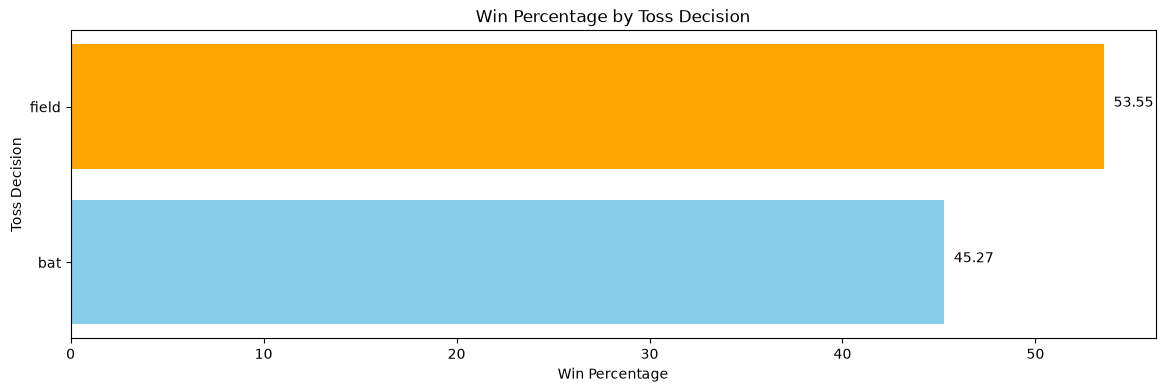

In [110]:
# Barh chart
df = df.sort_values(by="win_percentage")
plt.figure(figsize=(14,4))
plt.barh(df["toss_decision"],df["win_percentage"],color=["skyblue","orange"])
for i, v in enumerate(df["win_percentage"]):
    plt.text(v + 0.5, i, str(v))
plt.xlabel("Win Percentage")
plt.ylabel("Toss Decision")
plt.title("Win Percentage by Toss Decision")
plt.show()

#### Insights

#### Conclusion

#### analysis #9 Who are the most dangerous batters in IPL death overs?

In [111]:
query = """
            select batter, sum(batsman_runs) as runs,
            sum(case when extras_type = "wides" then 0 else 1 end) as balls,
            round((sum(batsman_runs) / sum(case when extras_type = "wides" then 0 else 1 end)) * 100, 2) as strike_rate
            from ipl_deliveries
            where `over` >= 15
            group by batter
            having balls >= 300
            order by strike_rate desc
            limit 10 ;
                      """
df = pd.read_sql(query, engine)
df.head()

,batter,runs,balls,strike_rate
0,AB de Villiers,1868.0,838.0,222.91
1,RR Pant,923.0,454.0,203.30
2,JC Buttler,596.0,302.0,197.35
3,AD Russell,1324.0,681.0,194.42
4,SV Samson,780.0,410.0,190.24


Text(0.5, 1.0, 'Top 10 Most Dangerous Death Over Batters in IPL')

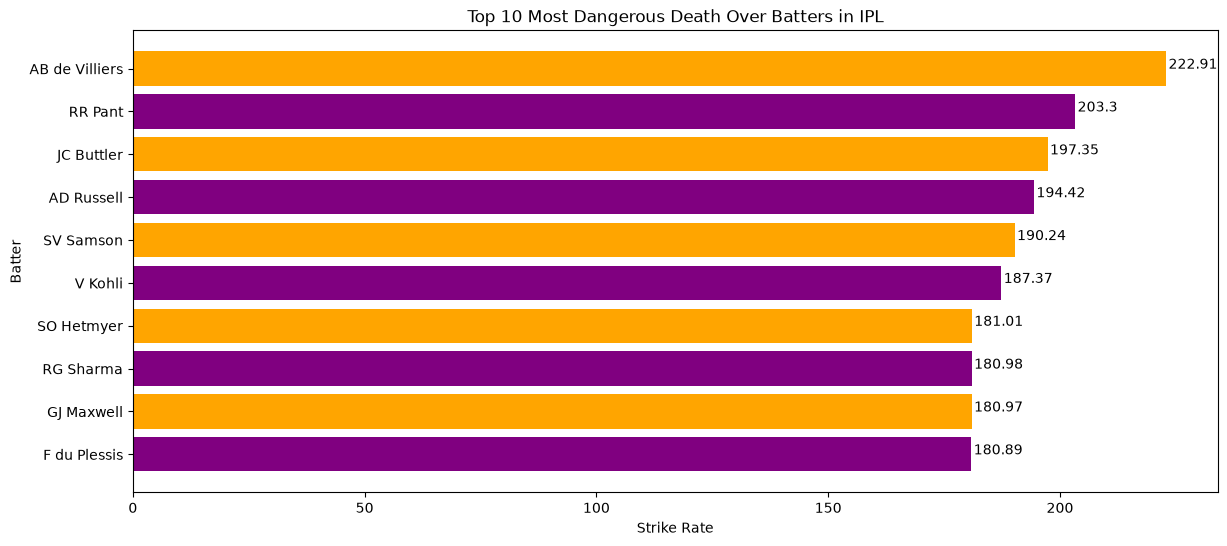

In [112]:
# Barh chart
df = df.sort_values(by="strike_rate")
plt.figure(figsize=(14,6))
bars = plt.barh(df["batter"],df["strike_rate"],color = ["purple", "orange"])
for i, v in enumerate(df["strike_rate"]) :
    plt.text(v + 0.5, i, str(v))
plt.xlabel("Strike Rate")
plt.ylabel("Batter")
plt.title("Top 10 Most Dangerous Death Over Batters in IPL")

#### Insights

#### Conclusion

#### analysis #10 How do team victories vary across different IPL stadiums?

In [113]:
query = """
            select stadium_name, winner, count(*) as wins
            from ipl_matches
            where winner not in ("no_result")
            group by stadium_name, winner 
            order by wins desc ;
                                """
df = pd.read_sql(query, engine)
df.head()

,stadium_name,winner,wins
0,Eden Gardens,Kolkata Knight Riders,52
1,Wankhede Stadium,Mumbai Indians,52
2,Chepauk Stadium,Chennai Super Kings,50
3,Chinnaswamy Stadium,Royal Challengers Bengaluru,44
4,Arun Jaitley Stadium,Delhi Capitals,37


In [114]:
pivot_df = df.pivot(
    index='winner',
    columns='stadium_name',
    values='wins'
)
pivot_df = pivot_df.fillna(0)
pivot_df.head()

stadium_name,Arun Jaitley Stadium,"Barabati Stadium, Cuttack",Barsapara Stadium,Brabourne Stadium,"Brabourne Stadium, Mumbai",Buffalo Park,Chepauk Stadium,Chinnaswamy Stadium,DY Patil Stadium,Diamond Oval,...,"SMS Stadium, Jaipur","Sahara Stadium, Pune",Sharjah Stadium,St George's Park,SuperSport Park,"VCA Stadium, Nagpur",Vizag Stadium,Wanderers Stadium,Wankhede Stadium,Zayed Stadium
winner,,,,,,,,,,,,,,,,,,,,,
Chennai Super Kings,8.0,0.0,0.0,1.0,0.0,1.0,50.0,6.0,6.0,1.0,...,3.0,1.0,3.0,2.0,2.0,0.0,2.0,1.0,13.0,4.0
Deccan Chargers,2.0,3.0,0.0,0.0,0.0,0.0,2.0,1.0,2.0,1.0,...,0.0,1.0,0.0,0.0,2.0,2.0,0.0,2.0,1.0,0.0
Delhi Capitals,37.0,0.0,0.0,0.0,4.0,1.0,4.0,4.0,3.0,0.0,...,2.0,1.0,5.0,1.0,2.0,0.0,3.0,1.0,6.0,3.0
Gujarat Lions,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
Gujarat Titans,1.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,2.0,0.0,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0


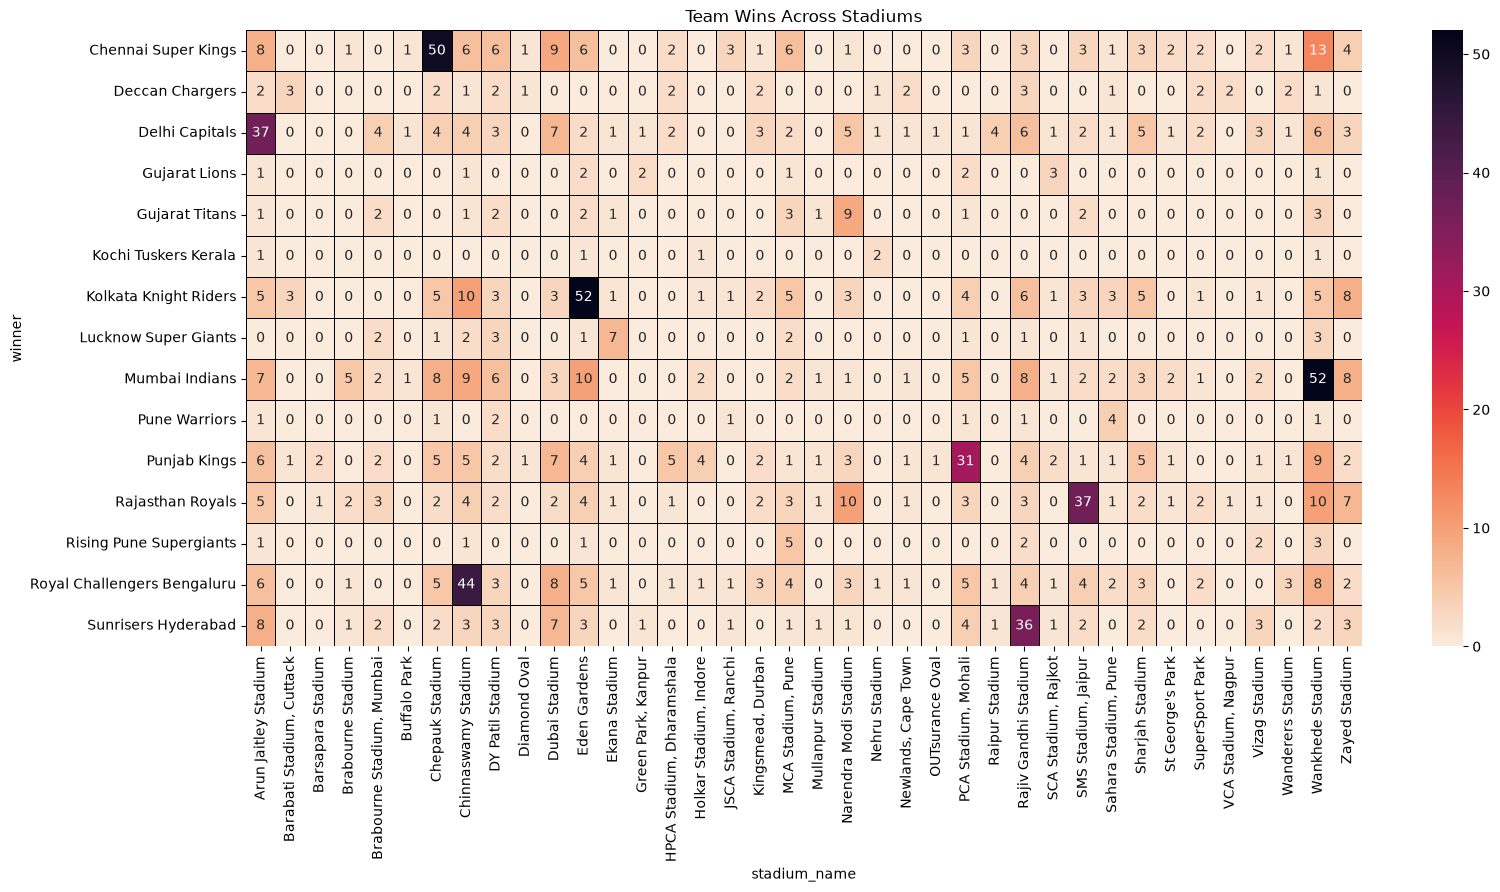

In [115]:
# Heatmap
plt.figure(figsize = (18, 8))
sns.heatmap(data = pivot_df, annot = True, cmap = "rocket_r", linewidth = 0.5, linecolor = "black")
plt.title('Team Wins Across Stadiums')
plt.show()

#### Insights

#### Conclusion

#### analysis #11 Which players have delivered the best batting and bowling performances in IPL knockout matches?

In [116]:
query = """
            select batter, count(distinct m.match_id) as matches,
            sum(batsman_runs) as total_runs
            from ipl_matches as m
            inner join ipl_deliveries as d
            on m.match_id = d.match_id
            where match_type not in ("3rd Place Play-Off", "League")
            group by batter
            order by total_runs desc
            limit 10  ;
                         """
df1 = pd.read_sql(query, engine)
df1["total_runs"] = df1["total_runs"].astype(int)

In [117]:
query = """
            select bowler, count(distinct m.match_id) as matches, 
            sum(is_wicket) as total_wicket
            from ipl_matches as m
            inner join ipl_deliveries as d
            on m.match_id = d.match_id
            where match_type not in ("3rd Place Play-Off", "League") and is_wicket = 1
            group by bowler
            order by total_wicket desc
            limit 10  ;
                        """
df2 = pd.read_sql(query, engine)
df2["total_wicket"] = df2["total_wicket"].astype(int)

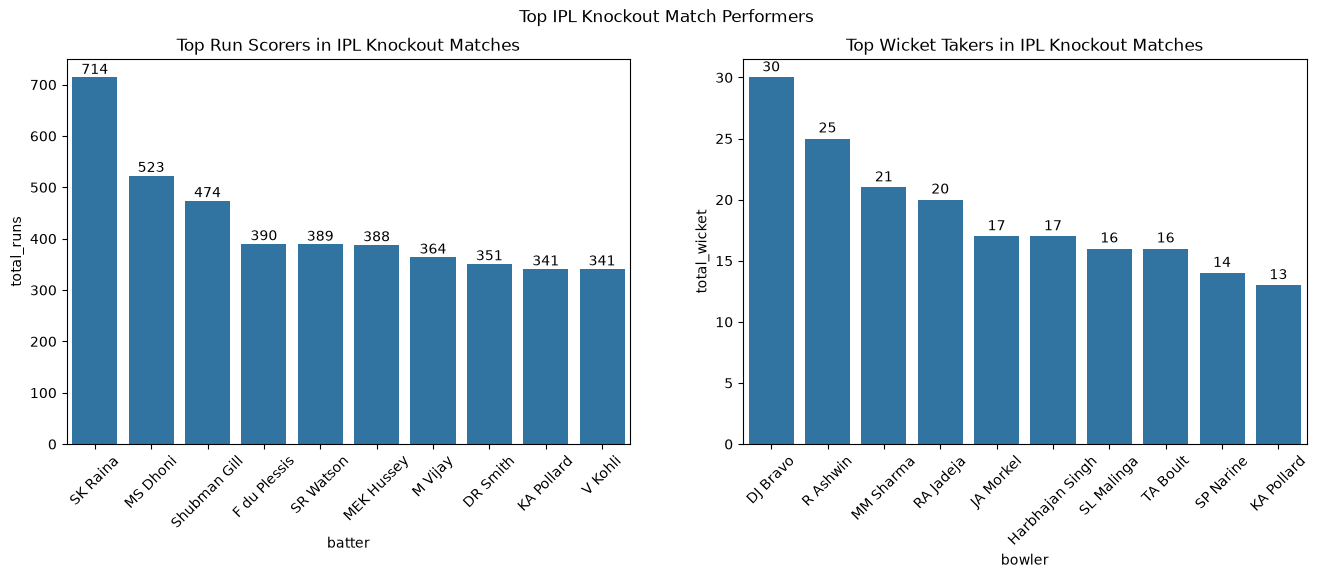

In [118]:
# subplot & bar chart
# bar chart1 1
plt.figure(figsize = (16, 5))
plt.subplot(1,2,1)
sns.barplot(data = df1, x = "batter", y = "total_runs", )
plt.title("Top Run Scorers in IPL Knockout Matches")
for i, value in enumerate(df1["total_runs"]):
    plt.text(i, value+ 7, str(value), ha='center')
plt.xticks(rotation=45)

# bar chart 2
plt.subplot(1,2,2)
sns.barplot(data = df2, x = "bowler", y = "total_wicket")
plt.title("Top Wicket Takers in IPL Knockout Matches")
for i, value in enumerate(df2["total_wicket"]):
    plt.text(i, value +0.5 , str(value), ha='center')
plt.xticks(rotation=45)
plt.suptitle("Top IPL Knockout Match Performers")
plt.show()

#### Insights

#### Conclusion

#### analysis #12 What is the distribution of total match scores in IPL?

In [119]:
query = """
            select stadium_name, d.match_id,
            sum(total_runs) as total_match_runs
            from ipl_matches as m
            inner join ipl_deliveries as d
            on m.match_id = d.match_id
            group by stadium_name, d.match_id ;
                      """
df = pd.read_sql(query, engine)
df.head()

,stadium_name,match_id,total_match_runs
0,Chinnaswamy Stadium,335982,304.0
1,"PCA Stadium, Mohali",335983,447.0
2,Arun Jaitley Stadium,335984,261.0
3,Wankhede Stadium,335985,331.0
4,Eden Gardens,335986,222.0


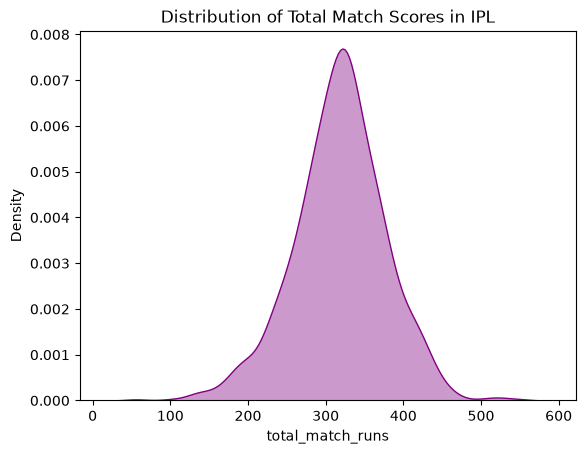

In [120]:
sns.kdeplot(data = df, x = "total_match_runs", fill = True, alpha = 0.4, color = "purple")
plt.title("Distribution of Total Match Scores in IPL")
plt.show()

#### Insights

#### Conclusion